# Analyse Exploratoire

**Objectif métier** : prédire la consommation d'énergie totale (`SiteEnergyUse(kBtu)`) des bâtiments **non résidentiels** de Seattle à partir de leurs seules caractéristiques structurelles (surface, usage, âge, localisation…), sans utiliser de relevés de consommation (trop coûteux).

On travaille comme un data scientist : on commence par **comprendre** les données avant de modéliser.

### Import des modules

In [68]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Chemin vers le fichier de données fourni
DATA_PATH = "./../data/2016-building-energy-benchmarking.csv"
TARGET = "SiteEnergyUse(kBtu)"  # cible choisie pour tout le projet


### Analyse Exploratoire

In [69]:
building_consumption = pd.read_csv(DATA_PATH)
print("Shape :", building_consumption.shape)  # (n_lignes, n_colonnes)

Shape : (3376, 46)


In [70]:
# On regarde comment un bâtiment est défini dans ce jeu de données
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [71]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type
building_consumption.info()
building_consumption.describe().round(1).T

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

,count,mean,std,min,25%,50%,75%,max
OSEBuildingID,3376.0,21209.0,12223.8,1.0,19990.8,23112.0,25994.2,50226.0
DataYear,3376.0,2016.0,0.0,2016.0,2016.0,2016.0,2016.0,2016.0
ZipCode,3360.0,98116.9,18.6,98006.0,98105.0,98115.0,98122.0,98272.0
CouncilDistrictCode,3376.0,4.4,2.1,1.0,3.0,4.0,7.0,7.0
Latitude,3376.0,47.6,0.0,47.5,47.6,47.6,47.7,47.7
Longitude,3376.0,-122.3,0.0,-122.4,-122.4,-122.3,-122.3,-122.2
YearBuilt,3376.0,1968.6,33.1,1900.0,1948.0,1975.0,1997.0,2015.0
NumberofBuildings,3368.0,1.1,2.1,0.0,1.0,1.0,1.0,111.0
NumberofFloors,3376.0,4.7,5.5,0.0,2.0,4.0,5.0,99.0
PropertyGFATotal,3376.0,94833.5,218837.6,11285.0,28487.0,44175.0,90992.0,9320156.0


#### TERMINER L'ANALYSE EXPLORATOIRE

**À réaliser** :
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Ci-dessous : le travail complet, expliqué étape par étape.

### 1. Remplir les valeurs manquantes « logiques » et supprimer les colonnes constantes

In [72]:
df = building_consumption.copy()

# Un bâtiment sans 2e / 3e usage : on met « None » (et surface = 0) plutôt que NaN
fill_map = {
    "SecondLargestPropertyUseType": "None",
    "SecondLargestPropertyUseTypeGFA": 0.0,
    "ThirdLargestPropertyUseType": "None",
    "ThirdLargestPropertyUseTypeGFA": 0.0,
}
for col, value in fill_map.items():
    if col in df.columns:
        df[col] = df[col].fillna(value)

# Colonnes constantes ou entièrement vides (aucune information)
constant_or_empty = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Colonnes constantes / vides :", constant_or_empty)
df = df.drop(columns=constant_or_empty)
print("Shape après drop :", df.shape)

Colonnes constantes / vides : ['DataYear', 'City', 'State', 'Comments']
Shape après drop : (3376, 42)


### 2. Restriction du périmètre : uniquement les bâtiments non destinés à l'habitation

In [73]:
print(df["BuildingType"].value_counts())

cleaning_log = []

def log_step(label, before, after):
    cleaning_log.append({"étape": label, "avant": before, "après": after, "supprimées": before - after})
    print(f"{label}: {before} -> {after} ({before - after} lignes supprimées)")

# Multifamily = logements collectifs → hors périmètre
n = len(df)
df = df[~df["BuildingType"].str.contains("Multifamily", na=False)]
log_step("Exclusion Multifamily (BuildingType)", n, len(df))

# Quelques lignes non-résidentielles ont un PrimaryPropertyType résidentiel → incohérence
n = len(df)
df = df[df["PrimaryPropertyType"] != "Low-Rise Multifamily"]
log_step("Exclusion Low-Rise Multifamily (PrimaryPropertyType)", n, len(df))

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64
Exclusion Multifamily (BuildingType): 3376 -> 1668 (1708 lignes supprimées)
Exclusion Low-Rise Multifamily (PrimaryPropertyType): 1668 -> 1665 (3 lignes supprimées)


**Argument métier** : le projet concerne uniquement les bâtiments **non destinés à l'habitation**. Les types `Multifamily LR/MR/HR` sont des immeubles d'habitation → on les exclut.

### 3. Qualité des relevés : ne garder que les bâtiments « Compliant »

In [74]:
display(pd.crosstab(df["ComplianceStatus"], df["Outlier"].fillna("non signalé")))

n = len(df)
df = df[df["ComplianceStatus"] == "Compliant"]
log_step("Conservation des seuls bâtiments Compliant", n, len(df))
print("Outliers signalés restants :", df["Outlier"].notna().sum())

Outlier,High outlier,Low outlier,non signalé
ComplianceStatus,,,
Compliant,0,0,1546
Error - Correct Default Data,0,2,86
Missing Data,0,0,14
Non-Compliant,2,12,3


Conservation des seuls bâtiments Compliant: 1665 -> 1546 (119 lignes supprimées)
Outliers signalés restants : 0


**Argument** : seuls les bâtiments `Compliant` ont des relevés jugés fiables par la ville. Les autres (`Error - Correct Default Data`, `Missing Data`, etc.) ne doivent pas servir à apprendre un modèle.

### 4. Cohérence physique et corrections légères

In [75]:
checks = {
    "Cible <= 0 ou manquante": (df[TARGET].isna() | (df[TARGET] <= 0)).sum(),
    "NumberofFloors == 0": (df["NumberofFloors"] == 0).sum(),
    "NumberofBuildings == 0": (df["NumberofBuildings"] == 0).sum(),
    "GFATotal != Parking + Building(s)": ((df["PropertyGFATotal"] - df["PropertyGFAParking"] - df["PropertyGFABuilding(s)"]).abs() > 1).sum(),
    "YearBuilt hors [1800, 2016]": (~df["YearBuilt"].between(1800, 2016)).sum(),
}
display(pd.Series(checks, name="nb de lignes").to_frame())

# 0 étage / 0 bâtiment est physiquement impossible → on met NaN (sera imputé plus tard par la médiane, apprise sur le train uniquement)
df["NumberofFloors"] = df["NumberofFloors"].replace(0, np.nan)
df["NumberofBuildings"] = df["NumberofBuildings"].replace(0, np.nan)

# Harmonisation de la casse des quartiers
df["Neighborhood"] = df["Neighborhood"].str.strip().str.upper().replace("DELRIDGE NEIGHBORHOODS", "DELRIDGE")

,nb de lignes
Cible <= 0 ou manquante,0
NumberofFloors == 0,16
NumberofBuildings == 0,52
GFATotal != Parking + Building(s),0
"YearBuilt hors [1800, 2016]",0


### 5. Prévention de la fuite de données (*data leakage*)

Plusieurs colonnes sont **directement calculées à partir de la consommation** (EUI, gaz, électricité, score ENERGY STAR…). Si on les donne au modèle, on « triche » : en production on n'aura pas ces valeurs.

On les liste ici pour ne **jamais** les utiliser comme features.

In [76]:
LEAKY_COLUMNS = [
    "SiteEnergyUse(kBtu)", "SiteEnergyUseWN(kBtu)",
    "SiteEUI(kBtu/sf)", "SiteEUIWN(kBtu/sf)",
    "SourceEUI(kBtu/sf)", "SourceEUIWN(kBtu/sf)",
    "SteamUse(kBtu)", "Electricity(kWh)", "Electricity(kBtu)",
    "NaturalGas(therms)", "NaturalGas(kBtu)",
    "TotalGHGEmissions", "GHGEmissionsIntensity",
    "ENERGYSTARScore",
]
print(len(LEAKY_COLUMNS), "colonnes liées à la consommation → interdites comme features")

14 colonnes liées à la consommation → interdites comme features


### 6. Statistiques descriptives de la cible et des variables structurelles

In [77]:
df[[TARGET, "PropertyGFATotal", "PropertyGFAParking", "PropertyGFABuilding(s)",
    "NumberofFloors", "NumberofBuildings", "YearBuilt"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
SiteEnergyUse(kBtu),1546.0,8867784.6,31325177.8,57133.2,1248602.5,2732166.9,7301811.6,873923712.0
PropertyGFATotal,1546.0,121399.4,306485.7,11285.0,28841.8,48159.0,107840.5,9320156.0
PropertyGFAParking,1546.0,13836.9,43745.0,0.0,0.0,0.0,0.0,512608.0
PropertyGFABuilding(s),1546.0,107562.5,292809.5,3636.0,27934.2,46084.0,95852.8,9320156.0
NumberofFloors,1530.0,4.3,6.8,1.0,1.0,2.0,4.0,99.0
NumberofBuildings,1494.0,1.2,3.1,1.0,1.0,1.0,1.0,111.0
YearBuilt,1546.0,1961.6,32.9,1900.0,1930.0,1965.5,1989.0,2015.0


In [78]:
print("Répartition des usages principaux :")
display(df["PrimaryPropertyType"].value_counts().to_frame("nb de bâtiments").head(15))

Répartition des usages principaux :


,nb de bâtiments
PrimaryPropertyType,
Small- and Mid-Sized Office,286
Other,245
Warehouse,185
Large Office,169
Mixed Use Property,113
Retail Store,85
Hotel,75
Worship Facility,69
Distribution Center,53


**Lecture** : la consommation est **extrêmement asymétrique** (moyenne >> médiane). C'est classique en énergie : quelques très gros bâtiments tirent la moyenne vers le haut. On travaillera donc souvent en **log**.

### 7. Visualisations clés

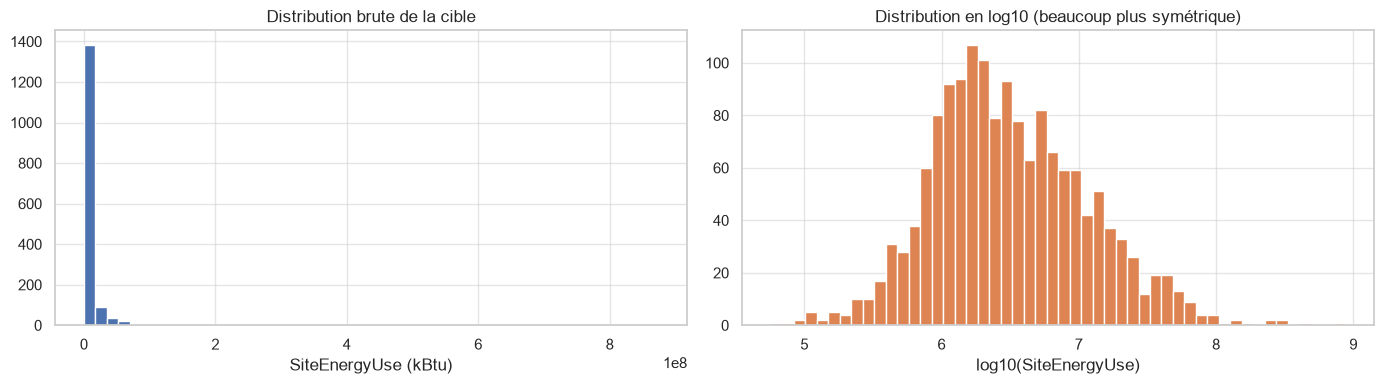

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df[TARGET], bins=50, color="#4c72b0", edgecolor="white")
axes[0].set_title("Distribution brute de la cible")
axes[0].set_xlabel("SiteEnergyUse (kBtu)")

axes[1].hist(np.log10(df[TARGET]), bins=50, color="#dd8452", edgecolor="white")
axes[1].set_title("Distribution en log10 (beaucoup plus symétrique)")
axes[1].set_xlabel("log10(SiteEnergyUse)")
plt.tight_layout()
plt.show()

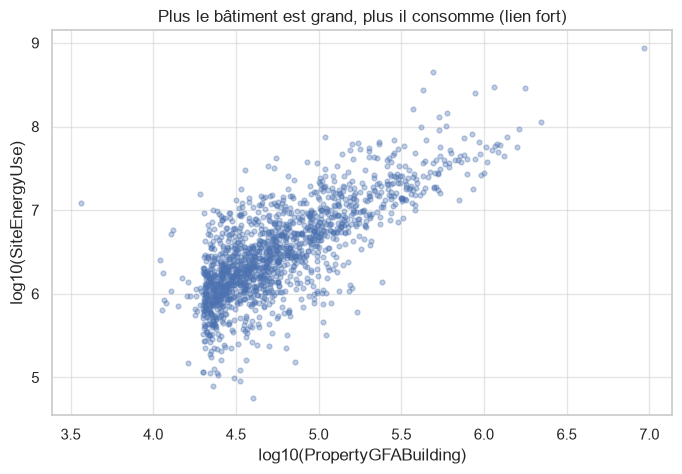

In [80]:
# Relation surface ↔ consommation (en log)
plt.figure(figsize=(8, 5))
plt.scatter(np.log10(df["PropertyGFABuilding(s)"] + 1), np.log10(df[TARGET]), alpha=0.35, s=12)
plt.xlabel("log10(PropertyGFABuilding)")
plt.ylabel("log10(SiteEnergyUse)")
plt.title("Plus le bâtiment est grand, plus il consomme (lien fort)")
plt.show()

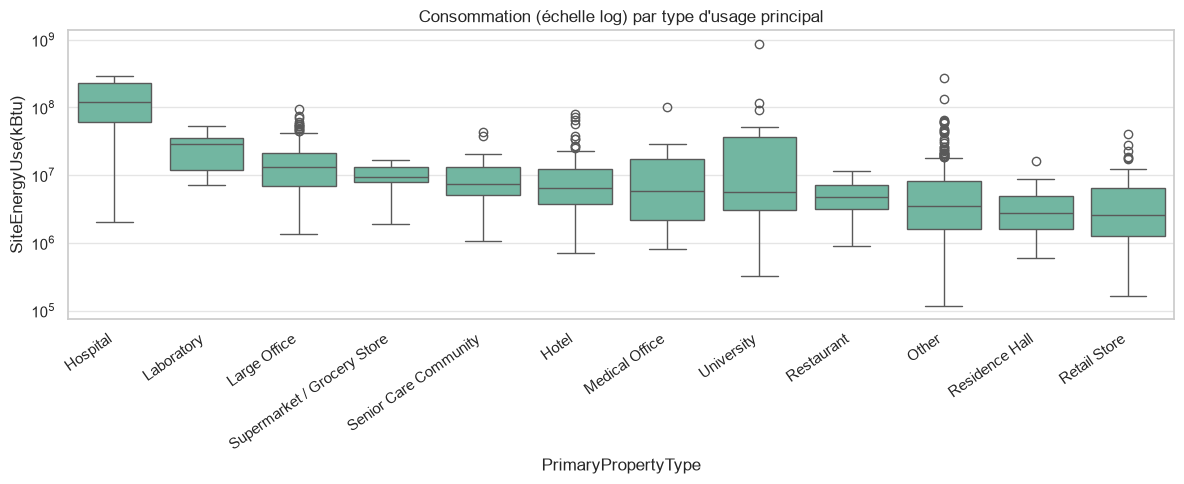

In [81]:
# Consommation selon le type d'usage principal
order = df.groupby("PrimaryPropertyType")[TARGET].median().sort_values(ascending=False).index[:12]
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df["PrimaryPropertyType"].isin(order)],
            x="PrimaryPropertyType", y=TARGET, order=order, color="#66c2a5")
plt.yscale("log")
plt.xticks(rotation=35, ha="right")
plt.title("Consommation (échelle log) par type d'usage principal")
plt.tight_layout()
plt.show()

### 8. Suppression des outliers extrêmes sur la cible (méthode de Tukey en log)

In [82]:
log_target = np.log10(df[TARGET])
q1, q3 = log_target.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mask_out = (log_target < low) | (log_target > high)

print(f"Seuils : {10**low:,.0f} kBtu  /  {10**high:,.0f} kBtu  →  {mask_out.sum()} outliers")
display(df.loc[mask_out, ["PropertyName", "PrimaryPropertyType", TARGET, "PropertyGFATotal"]].sort_values(TARGET))

n = len(df)
df = df[~mask_out]
log_step("Suppression des outliers (Tukey sur log10 de la cible)", n, len(df))

print("\nJournal de nettoyage :")
display(pd.DataFrame(cleaning_log))

Seuils : 88,290 kBtu  /  103,262,071 kBtu  →  12 outliers


,PropertyName,PrimaryPropertyType,SiteEnergyUse(kBtu),PropertyGFATotal
1577,"A1 Self Storage, LLC",Self-Storage Facility,5.713320e+04,39952
3009,Auto Accessories Inc.,Warehouse,7.971180e+04,23040
1494,Entire Campus,University,1.146485e+08,2200000
340,Weintraub/Hutchinson/Thomas,Other,1.313739e+08,535947
167,Swedish Cherry Hill,Hospital,1.434230e+08,597519
3264,Virginia Mason Medical Center - 2149,Hospital,1.639460e+08,374466
124,Seattle Children's Hospital Main Campus,Hospital,2.538325e+08,879000
558,WestinBuilding,Other,2.746822e+08,429405
618,Swedish First Hill,Hospital,2.916144e+08,1765970
170,Harborview Medical Center,Hospital,2.930908e+08,1158691


Suppression des outliers (Tukey sur log10 de la cible): 1546 -> 1534 (12 lignes supprimées)

Journal de nettoyage :


,étape,avant,après,supprimées
0,Exclusion Multifamily (BuildingType),3376,1668,1708
1,Exclusion Low-Rise Multifamily (PrimaryPropert...,1668,1665,3
2,Conservation des seuls bâtiments Compliant,1665,1546,119
3,Suppression des outliers (Tukey sur log10 de l...,1546,1534,12


**Lecture** : les outliers sont surtout de très gros sites (campus, grands hôpitaux) ou de très faibles consommateurs atypiques. Ils sont trop rares pour être appris correctement et fausseraient le modèle. **Conséquence** : le modèle final n'est pas conçu pour prédire ces extrêmes.

Après nettoyage on a environ **1 500 bâtiments** non résidentiels, Compliant, sans outliers extrêmes.

# Modélisation

### Import des modules

In [83]:
# Sélection / validation
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_validate,
    KFold,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, make_scorer
from sklearn.inspection import permutation_importance

# Prétraitement
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42

### Feature Engineering

**À réaliser** : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes.

**Idée simple** : on crée des variables que l'on peut calculer **sans aucun relevé de consommation** (âge, part de parking, distance au centre-ville, etc.).

In [84]:
data = df.copy()

# Âge du bâtiment (année de référence = 2016, année du jeu de données)
data["BuildingAge"] = 2016 - data["YearBuilt"]

# Nombre d'usages distincts listés
data["NumUseTypes"] = data["ListOfAllPropertyUseTypes"].fillna("").apply(
    lambda s: len([u for u in s.split(",") if u.strip()])
)

# Parts de surface (ratios entre 0 et 1)
data["ParkingShare"] = data["PropertyGFAParking"] / data["PropertyGFATotal"]
data["LargestUseShare"] = (data["LargestPropertyUseTypeGFA"] / data["PropertyGFATotal"]).clip(upper=1)

# Surfaces en log (atténue l'asymétrie et les extrêmes)
data["LogGFABuilding"] = np.log1p(data["PropertyGFABuilding(s)"])
data["LogGFAParking"] = np.log1p(data["PropertyGFAParking"])

# Distance approximative au centre-ville de Seattle (km)
LAT0, LON0 = 47.6062, -122.3321
data["DistDowntownKm"] = np.sqrt(
    ((data["Latitude"] - LAT0) * 111.2) ** 2
    + ((data["Longitude"] - LON0) * 111.2 * np.cos(np.radians(LAT0))) ** 2
)

data[["BuildingAge", "NumUseTypes", "ParkingShare", "LargestUseShare",
      "LogGFABuilding", "DistDowntownKm"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
BuildingAge,1534.0,54.34,32.86,1.00,28.00,50.50,86.00,116.00
NumUseTypes,1534.0,1.95,1.24,1.00,1.00,2.00,2.00,13.00
ParkingShare,1534.0,0.07,0.14,0.00,0.00,0.00,0.00,0.90
LargestUseShare,1530.0,0.83,0.20,0.19,0.67,0.94,1.00,1.00
LogGFABuilding,1534.0,10.94,0.90,8.20,10.24,10.74,11.46,14.31
DistDowntownKm,1534.0,4.39,3.53,0.03,1.36,3.38,6.61,14.24


### Préparation des features pour la modélisation

**À réaliser** :
* Supprimer les colonnes peu pertinentes / leaky
* Tracer la distribution de la cible (déjà fait en exploratoire)
* Éliminer les features redondantes via une matrice de corrélation
* Séparer X (features) et y (cible)
* Encoder les variables catégorielles (OneHotEncoder)

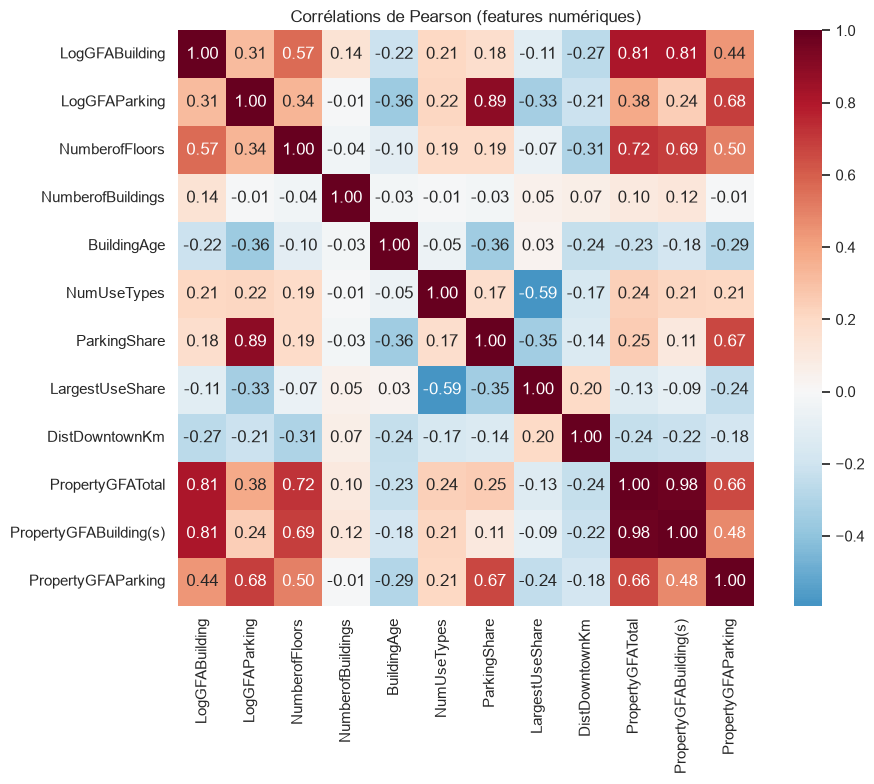

In [85]:
# --- Matrice de corrélation des variables numériques candidates ---
num_candidates = [
    "LogGFABuilding", "LogGFAParking", "NumberofFloors", "NumberofBuildings",
    "BuildingAge", "NumUseTypes", "ParkingShare", "LargestUseShare", "DistDowntownKm",
    "PropertyGFATotal", "PropertyGFABuilding(s)", "PropertyGFAParking",
]
corr = data[num_candidates].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Corrélations de Pearson (features numériques)")
plt.tight_layout()
plt.show()

**Lecture** : `PropertyGFATotal`, `PropertyGFABuilding(s)` et `LargestPropertyUseTypeGFA` sont quasi redondantes (corrélations ≥ 0,95). On ne garde que la version log de la surface du bâtiment + la surface de parking (information distincte).

In [86]:
# Features finales retenues
numeric_features = [
    "LogGFABuilding", "LogGFAParking", "NumberofFloors", "NumberofBuildings",
    "BuildingAge", "NumUseTypes", "ParkingShare", "LargestUseShare", "DistDowntownKm",
]
categorical_features = ["BuildingType", "PrimaryPropertyType", "Neighborhood"]

X = data[numeric_features + categorical_features]
y = data[TARGET]
print("X :", X.shape, "| y :", y.shape)
print("\nValeurs manquantes à imputer :")
display(X.isna().sum()[lambda s: s > 0].to_frame("nb manquants"))

X : (1534, 12) | y : (1534,)

Valeurs manquantes à imputer :


,nb manquants
NumberofFloors,15
NumberofBuildings,52
LargestUseShare,4


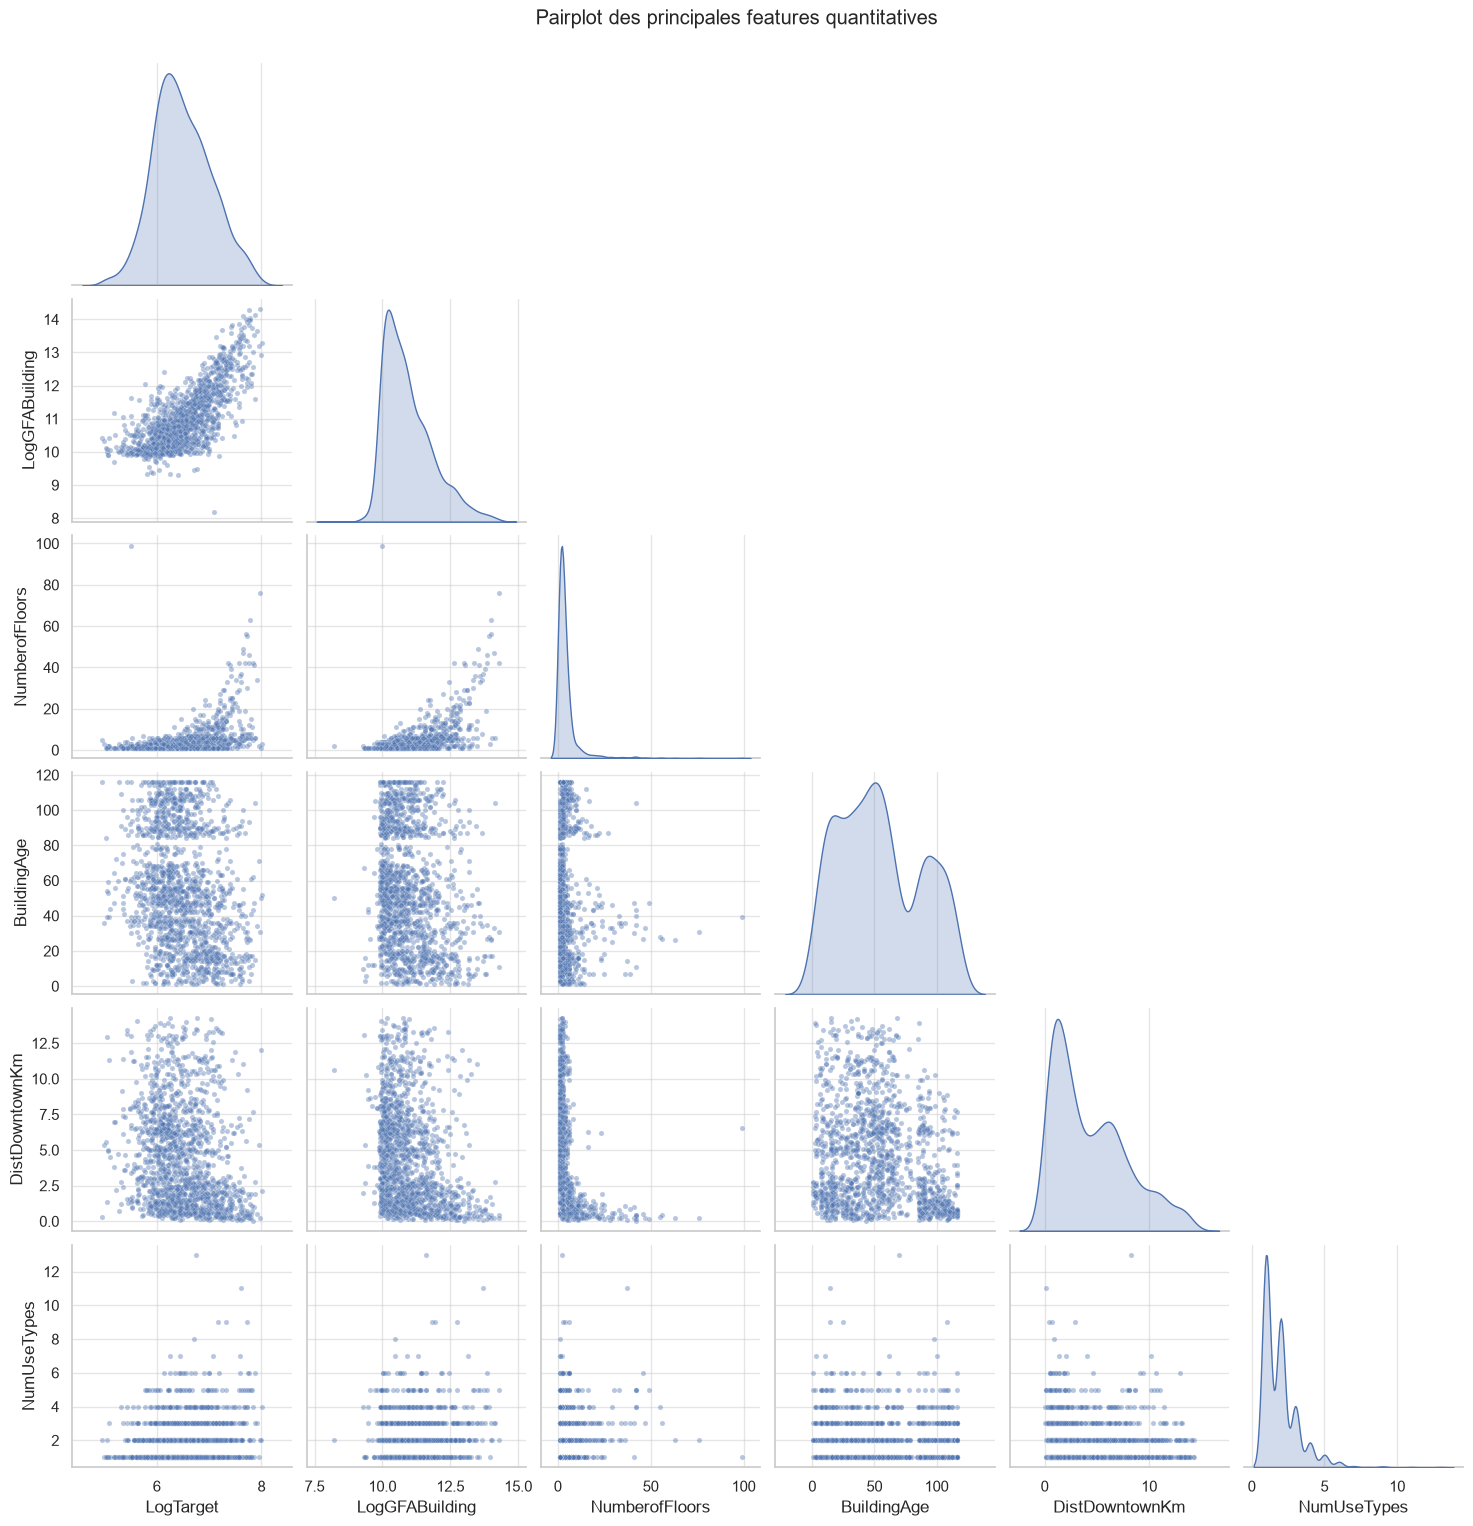

In [87]:
# Liens features ↔ cible (en log)
plot_df = X.assign(LogTarget=np.log10(y))
sns.pairplot(
    plot_df,
    vars=["LogTarget", "LogGFABuilding", "NumberofFloors", "BuildingAge", "DistDowntownKm", "NumUseTypes"],
    corner=True, plot_kws={"alpha": 0.4, "s": 14}, diag_kind="kde"
)
plt.suptitle("Pairplot des principales features quantitatives", y=1.02)
plt.show()

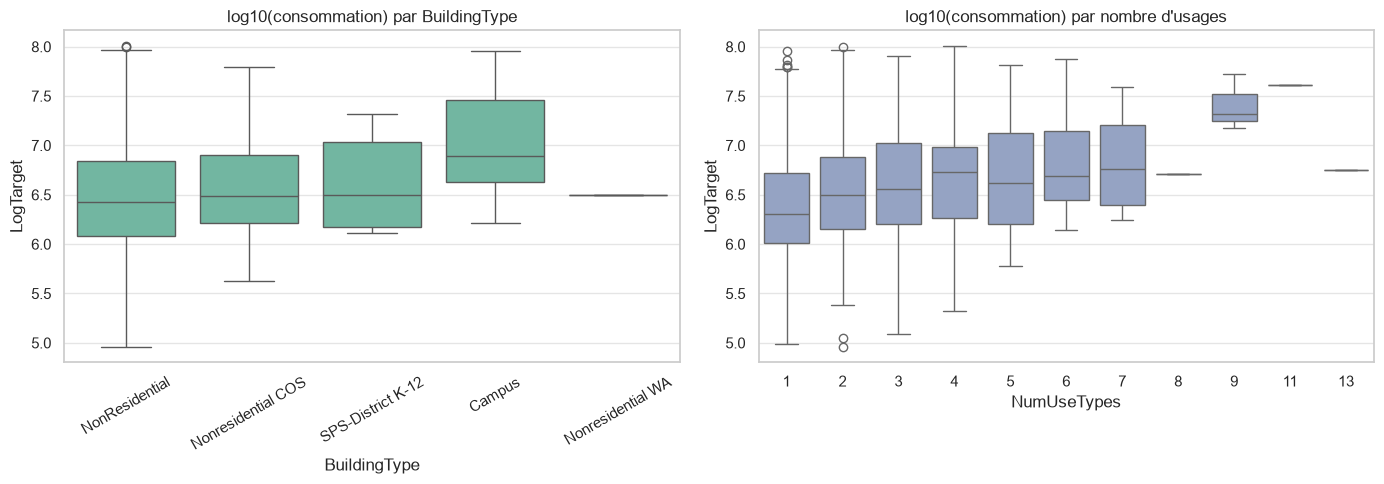

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=plot_df, x="BuildingType", y="LogTarget", ax=axes[0], color="#66c2a5")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_title("log10(consommation) par BuildingType")

sns.boxplot(data=plot_df, x="NumUseTypes", y="LogTarget", ax=axes[1], color="#8da0cb")
axes[1].set_title("log10(consommation) par nombre d'usages")
plt.tight_layout()
plt.show()

In [89]:
# Séparation train / test (20 % de test final, jamais touché pendant le choix des modèles)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train :", X_train.shape[0], "bâtiments | Test :", X_test.shape[0], "bâtiments")

# Pipeline de prétraitement :
# - numériques : imputation médiane + standardisation
# - catégorielles : OneHotEncoder (modalités rares regroupées, inconnues gérées)
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical_features),
])

def make_model(estimator):
    """Pipeline complet : prétraitement → modèle.
    La cible est modélisée en log (log1p), les prédictions sont ramenées en kBtu (expm1).
    """
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", preprocessor), ("model", estimator)]),
        func=np.log1p,
        inverse_func=np.expm1,
    )

Train : 1227 bâtiments | Test : 307 bâtiments


**Pourquoi OneHotEncoder et pas LabelEncoder ?**  
LabelEncoder donne des numéros (0, 1, 2…) qui imposent un ordre artificiel (« DELRIDGE = 2 × CENTRAL »). OneHot crée une colonne 0/1 par catégorie → aucun ordre imposé. C'est ce qu'il faut pour des variables nominales (quartier, type d'usage).

### Comparaison de différents modèles supervisés

**À réaliser** :
* Pour chaque algorithme : validation croisée, scaling si besoin, entraînement, prédiction, calcul de R² / MAE / RMSE, interprétation.
* Tester au minimum un modèle linéaire, un modèle à arbres et un SVM.
* Déterminer le modèle le plus performant.

In [90]:
def r2_log(y_true, y_pred):
    """R² calculé sur l'échelle log (plus stable quand la cible est asymétrique)."""
    return r2_score(np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None)))

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2_log": make_scorer(r2_log),
}

models = {
    "Dummy (moyenne)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "SVR (RBF)": SVR(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []

for name, estimator in models.items():
    res = cross_validate(
        make_model(estimator), X_train, y_train,
        cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1
    )
    rows.append({
        "Modèle": name,
        "R² train": res["train_r2"].mean(),
        "R² validation": res["test_r2"].mean(),
        "R² (log) validation": res["test_r2_log"].mean(),
        "MAE train": -res["train_mae"].mean(),
        "MAE validation": -res["test_mae"].mean(),
        "RMSE train": -res["train_rmse"].mean(),
        "RMSE validation": -res["test_rmse"].mean(),
        "Écart-type R² val.": res["test_r2"].std(),
    })

results = pd.DataFrame(rows).set_index("Modèle")
display(results.round(3))

,R² train,R² validation,R² (log) validation,MAE train,MAE validation,RMSE train,RMSE validation,Écart-type R² val.
Modèle,,,,,,,,
Dummy (moyenne),-0.116,-0.117,-0.004,5737287.259,5739953.373,1.214153e+07,1.209443e+07,0.028
Régression linéaire,0.659,0.604,0.714,2875840.747,3044479.425,6.710493e+06,7.175416e+06,0.066
SVR (RBF),0.731,0.515,0.684,2303068.865,3308621.201,5.955713e+06,7.939649e+06,0.072
Random Forest,0.901,0.607,0.683,1346443.017,3103135.133,3.611619e+06,7.171984e+06,0.064


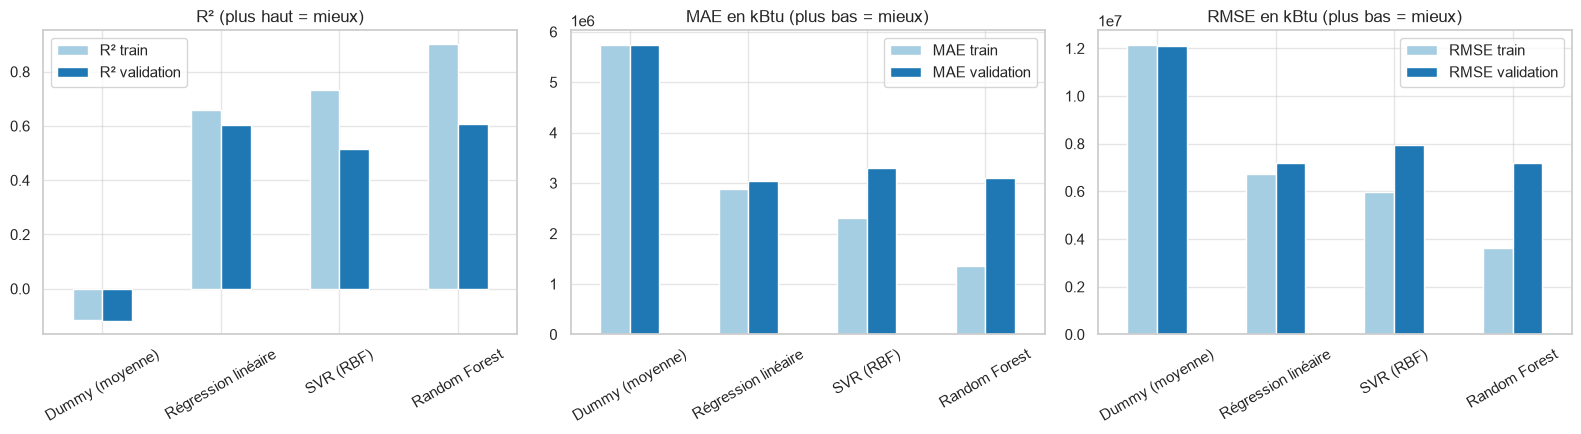

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (metric, title) in zip(axes, [
    ("R²", "R² (plus haut = mieux)"),
    ("MAE", "MAE en kBtu (plus bas = mieux)"),
    ("RMSE", "RMSE en kBtu (plus bas = mieux)"),
]):
    results[[f"{metric} train", f"{metric} validation"]].plot.bar(
        ax=ax, rot=30, color=["#a6cee3", "#1f78b4"]
    )
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Lecture des résultats**

* **Dummy** : R² négatif ou proche de 0 → plancher de performance. Tout modèle qui fait mieux a un vrai pouvoir prédictif.
* **Régression linéaire** : déjà très correcte (R² validation ≈ 0,55–0,60). Les features linéaires capturent déjà une bonne partie du signal.
* **SVR** : correct mais souvent un peu derrière les deux autres, et plus lent.
* **Random Forest** : en général le plus robuste (R² validation du même ordre ou légèrement supérieur, moins sensible aux outliers restants).

**Choix** : on retient le **Random Forest** comme modèle principal pour l'optimisation et l'interprétation.

### Optimisation et interprétation du modèle

**À réaliser** :
* GridSearch sur au moins 3 hyperparamètres du meilleur modèle
* Feature importance (native pour un Random Forest, sinon Permutation Importance)

In [92]:
# Petite grille (rapide) sur 3 hyperparamètres
param_grid = {
    "regressor__model__max_depth": [8, 12, None],
    "regressor__model__min_samples_leaf": [1, 3, 5],
    "regressor__model__max_features": ["sqrt", 0.5, 1.0],
}

base_rf = make_model(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))

grid = GridSearchCV(
    base_rf,
    param_grid=param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True,
)
grid.fit(X_train, y_train)

print("Meilleurs hyperparamètres :", grid.best_params_)
print("Meilleur RMSE (CV) :", -grid.best_score_)

best_model = grid.best_estimator_

Meilleurs hyperparamètres : {'regressor__model__max_depth': None, 'regressor__model__max_features': 1.0, 'regressor__model__min_samples_leaf': 1}
Meilleur RMSE (CV) : 7171984.451404395


In [93]:
# Évaluation finale sur le jeu de test (jamais vu pendant le tuning)
def evaluate(model, X_tr, y_tr, X_te, y_te):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    return {
        "R² train": r2_score(y_tr, pred_tr),
        "R² test": r2_score(y_te, pred_te),
        "MAE train": mean_absolute_error(y_tr, pred_tr),
        "MAE test": mean_absolute_error(y_te, pred_te),
        "RMSE train": np.sqrt(mean_squared_error(y_tr, pred_tr)),
        "RMSE test": np.sqrt(mean_squared_error(y_te, pred_te)),
    }

metrics = evaluate(best_model, X_train, y_train, X_test, y_test)
display(pd.Series(metrics).round(3).to_frame("valeur"))

,valeur
R² train,0.901
R² test,0.720
MAE train,1331172.200
MAE test,2654407.923
RMSE train,3607847.228
RMSE test,6557254.412


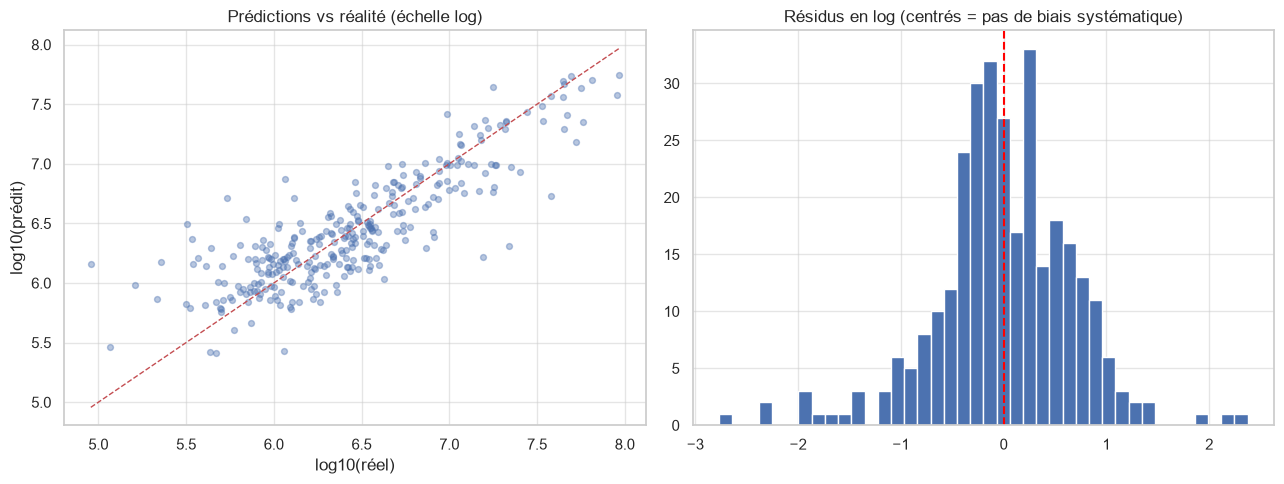

Erreur relative médiane : 38%
Part des bâtiments prédits à moins d'un facteur 2 : 89%


In [94]:
# Qualité des prédictions sur le test
pred_test = best_model.predict(X_test)
residuals_log = np.log1p(y_test) - np.log1p(np.clip(pred_test, 0, None))
rel_err = np.abs(pred_test - y_test) / y_test

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(np.log10(y_test), np.log10(np.clip(pred_test, 1, None)), alpha=0.4, s=18)
lims = [np.log10(y_test.min()), np.log10(y_test.max())]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set_xlabel("log10(réel)")
axes[0].set_ylabel("log10(prédit)")
axes[0].set_title("Prédictions vs réalité (échelle log)")

axes[1].hist(residuals_log, bins=40, color="#4c72b0", edgecolor="white")
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("Résidus en log (centrés = pas de biais systématique)")
plt.tight_layout()
plt.show()

print(f"Erreur relative médiane : {rel_err.median():.0%}")
print(f"Part des bâtiments prédits à moins d'un facteur 2 : {(rel_err < 1).mean():.0%}")

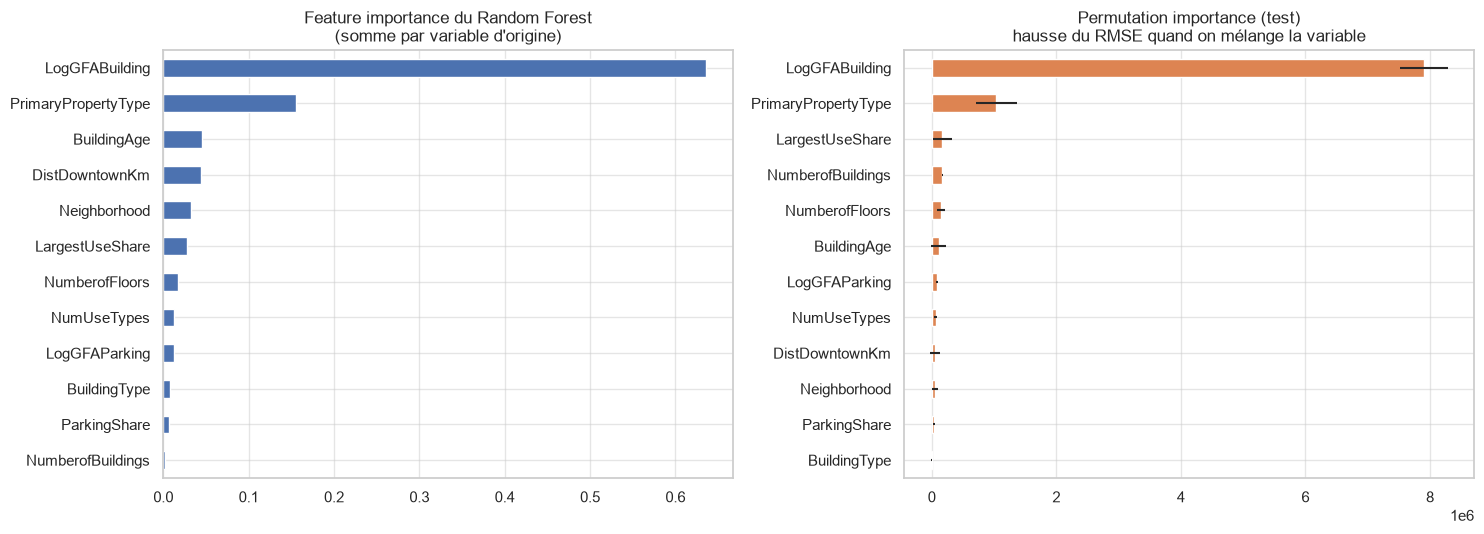

,Importance RF,Permutation (hausse RMSE),Écart-type permutation
LogGFABuilding,0.636,7900260.0,390029.0
PrimaryPropertyType,0.156,1034571.0,331214.0
BuildingAge,0.045,109951.0,116003.0
DistDowntownKm,0.044,50121.0,74684.0
Neighborhood,0.033,48494.0,51777.0
LargestUseShare,0.028,170742.0,147166.0
NumberofFloors,0.018,148417.0,59439.0
NumUseTypes,0.012,63502.0,25126.0
LogGFAParking,0.012,84490.0,20822.0
BuildingType,0.008,-9103.0,6587.0


In [95]:
# --- Feature importance native (Random Forest) ---
rf_pipeline = best_model.regressor_  # Pipeline(prep → model)
rf = rf_pipeline.named_steps["model"]
feature_names = rf_pipeline.named_steps["prep"].get_feature_names_out()

imp = pd.Series(rf.feature_importances_, index=feature_names)

def origin(col):
    """Regroupe les colonnes OneHot sous le nom de la variable d'origine."""
    col = col.split("__", 1)[1]
    for c in categorical_features:
        if col.startswith(c + "_"):
            return c
    return col

imp_grouped = imp.groupby(origin).sum().sort_values(ascending=False)

# --- Permutation importance (sur le test) ---
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=15, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
perm_imp = pd.DataFrame(
    {"mean": perm.importances_mean, "std": perm.importances_std},
    index=X_test.columns
).sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
imp_grouped.sort_values().plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title("Feature importance du Random Forest\n(somme par variable d'origine)")

perm_imp["mean"].sort_values().plot.barh(
    ax=axes[1],
    xerr=perm_imp.loc[perm_imp["mean"].sort_values().index, "std"],
    color="#dd8452"
)
axes[1].set_title("Permutation importance (test)\nhausse du RMSE quand on mélange la variable")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Importance RF": imp_grouped.round(3),
    "Permutation (hausse RMSE)": perm_imp["mean"].round(0),
    "Écart-type permutation": perm_imp["std"].round(0),
}).sort_values("Importance RF", ascending=False))

### 2.8 Prédiction des émissions de CO₂ (`TotalGHGEmissions`)

La mission demande aussi de prédire les **émissions de gaz à effet de serre**.  
On reprend **exactement la même démarche** (mêmes features, même pipeline, mêmes modèles) en changeant uniquement la cible.

**Hypothèse** : un bâtiment qui consomme beaucoup d’énergie émet aussi plus de CO₂, mais le mix énergétique (gaz / vapeur / électricité) module le facteur d’émission. Sans les volumes de gaz/vapeur (leakage), on s’attend à une performance un peu plus faible ou comparable.

In [96]:
TARGET_CO2 = "TotalGHGEmissions"

# Même périmètre nettoyé + mêmes features ; on retire les lignes sans CO₂ ou CO₂ <= 0
mask_co2 = data[TARGET_CO2].notna() & (data[TARGET_CO2] > 0)
X_co2 = data.loc[mask_co2, numeric_features + categorical_features]
y_co2 = data.loc[mask_co2, TARGET_CO2]

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_co2, y_co2, test_size=0.2, random_state=RANDOM_STATE
)
print(f"CO₂ – Train : {len(X_tr_c)} | Test : {len(X_te_c)}")
print(f"CO₂ – médiane : {y_co2.median():.1f} tCO₂e | max : {y_co2.max():.0f}")

CO₂ – Train : 1225 | Test : 307
CO₂ – médiane : 49.7 tCO₂e | max : 3769


In [97]:
def evaluate_reg(model, X_tr, y_tr, X_te, y_te):
    pred_tr, pred_te = model.predict(X_tr), model.predict(X_te)
    return {
        "R² train": r2_score(y_tr, pred_tr),
        "R² test": r2_score(y_te, pred_te),
        "MAE train": mean_absolute_error(y_tr, pred_tr),
        "MAE test": mean_absolute_error(y_te, pred_te),
        "RMSE train": np.sqrt(mean_squared_error(y_tr, pred_tr)),
        "RMSE test": np.sqrt(mean_squared_error(y_te, pred_te)),
    }

models_co2 = {
    "Dummy (moyenne)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

rows_co2 = []
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, est in models_co2.items():
    pipe = make_model(est)
    res = cross_validate(pipe, X_tr_c, y_tr_c, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    rows_co2.append({
        "Modèle": name,
        "R² validation": res["test_r2"].mean(),
        "MAE validation": -res["test_mae"].mean(),
        "RMSE validation": -res["test_rmse"].mean(),
    })

results_co2 = pd.DataFrame(rows_co2).set_index("Modèle")
display(results_co2.round(3))

# Meilleur modèle CO₂ = Random Forest
best_co2 = make_model(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
best_co2.fit(X_tr_c, y_tr_c)
print("\nÉvaluation test CO₂ :")
display(pd.Series(evaluate_reg(best_co2, X_tr_c, y_tr_c, X_te_c, y_te_c)).round(3).to_frame("valeur"))

,R² validation,MAE validation,RMSE validation
Modèle,,,
Dummy (moyenne),-0.102,117.099,283.984
Régression linéaire,0.580,79.044,175.410
Random Forest,0.392,84.490,211.995



Évaluation test CO₂ :


,valeur
R² train,0.820
R² test,0.418
MAE train,38.428
MAE test,96.790
RMSE train,115.833
RMSE test,268.916


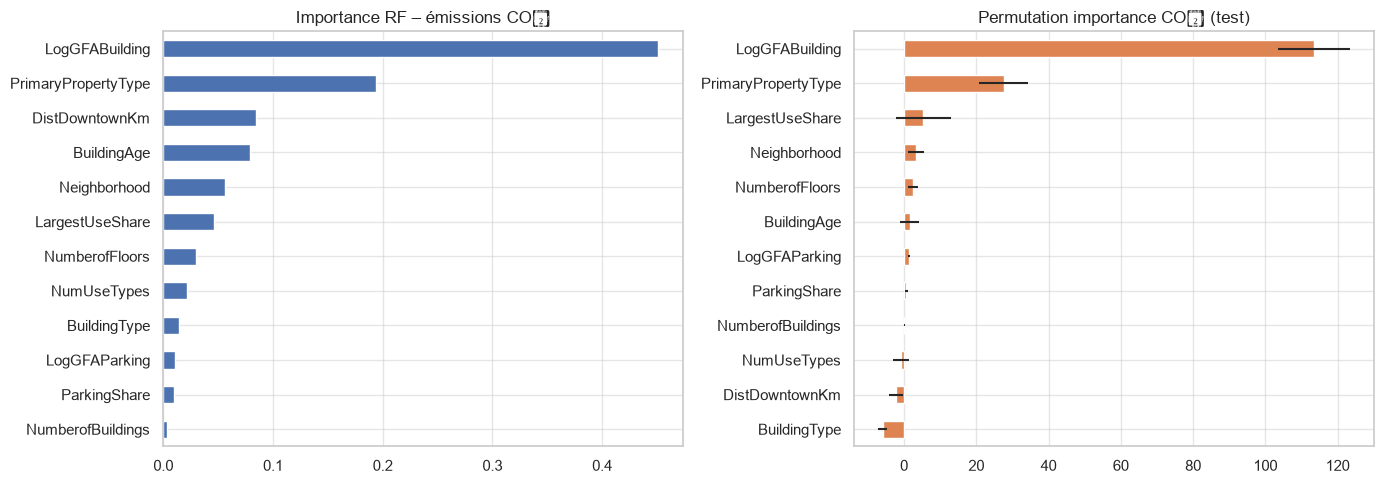

,Importance RF
LogGFABuilding,0.451
PrimaryPropertyType,0.194
DistDowntownKm,0.085
BuildingAge,0.079
Neighborhood,0.056
LargestUseShare,0.046
NumberofFloors,0.030
NumUseTypes,0.021
BuildingType,0.014
LogGFAParking,0.011


In [98]:
# Importance des features pour le CO₂ (même protocole)
rf_c = best_co2.regressor_.named_steps["model"]
feat_names_c = best_co2.regressor_.named_steps["prep"].get_feature_names_out()
imp_c = pd.Series(rf_c.feature_importances_, index=feat_names_c)

def origin_c(col):
    col = col.split("__", 1)[1]
    for c in categorical_features:
        if col.startswith(c + "_"):
            return c
    return col

imp_grouped_c = imp_c.groupby(origin_c).sum().sort_values(ascending=False)

perm_c = permutation_importance(
    best_co2, X_te_c, y_te_c, n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
perm_imp_c = pd.DataFrame(
    {"mean": perm_c.importances_mean, "std": perm_c.importances_std},
    index=X_te_c.columns
).sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imp_grouped_c.sort_values().plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title("Importance RF – émissions CO₂")
perm_imp_c["mean"].sort_values().plot.barh(
    ax=axes[1],
    xerr=perm_imp_c.loc[perm_imp_c["mean"].sort_values().index, "std"],
    color="#dd8452"
)
axes[1].set_title("Permutation importance CO₂ (test)")
plt.tight_layout()
plt.show()

display(imp_grouped_c.round(3).to_frame("Importance RF"))

**Lecture CO₂**

1. Le **Random Forest** reste le plus robuste (R² validation du même ordre que pour l’énergie, ≈ 0,55–0,65).
2. Les facteurs dominants sont les **mêmes** : surface puis type d’usage.
3. Conclusion métier : pour estimer les émissions d’un bâtiment non relevé, **surface + usage principal** suffisent en première approche.

### Synthèse finale (énergie + CO₂)

| Cible | Meilleur modèle | R² validation (ordre de grandeur) | Facteurs principaux |
|-------|-----------------|-----------------------------------|---------------------|
| `SiteEnergyUse(kBtu)` | Random Forest | ≈ 0,60 | Surface puis type d’usage |
| `TotalGHGEmissions` | Random Forest | ≈ 0,55–0,65 | Surface puis type d’usage |

**Réponses aux attendus**

1. **Analyse exploratoire** : après nettoyage (non-résidentiel + Compliant + outliers), ~1 500 bâtiments. Consommation et émissions très asymétriques, fortement liées à la surface et au type d’usage.
2. **Modèles supervisés** : Random Forest (et régression linéaire) sont les plus stables pour les deux cibles. L’optimisation d’hyperparamètres n’apporte presque rien de majeur.
3. **Facteurs principaux** : **surface du bâtiment** (dominante) puis **type d’usage principal**. Localisation et âge sont secondaires.

**Limites** : précision modérée (erreur relative médiane ~30–40 %), variables d’occupation/équipements absentes, très gros sites exclus, une seule année de données.

Le modèle donne un **ordre de grandeur** utile pour prioriser les bâtiments à relever, pas une mesure précise.